## House Price Prediction

#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1.Problem Statement
- This project aims to understand how house prices (`Price`) are affected by features such as  'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'.

### 2.Data Collection
- Data source:"https://www.kaggle.com/datasets/yasserh/housing-prices-dataset"
- The data consists of 13 columns and 545 rows

### Importing required packages

In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


### Importing the CSV data as DataFrame

In [181]:
import pandas as pd
df=pd.read_csv("data/Housing.csv")

In [182]:
#Top 5 records
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [183]:
#info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [184]:
#shape of the dataset
df.shape

(545, 13)

In [185]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

### Dataset information

- `price` : Price of the house (Target variable)
- `area` : Total area of the house (in sq. ft.)
- `bedrooms` : Number of bedrooms
- `bathrooms` : Number of bathrooms
- `stories` : Number of stories (floors)
- `mainroad` : Whether connected to the main road (`yes` / `no`)
- `guestroom` : Whether the house has a guest room (`yes` / `no`)
- `basement` : Whether the house has a basement (`yes` / `no`)
- `hotwaterheating` : Whether the house has hot water heating (`yes` / `no`)
- `airconditioning` : Whether the house has air conditioning (`yes` / `no`)
- `parking` : Number of house parking spaces
- `prefarea` : Whether located in a preferred area (`yes` / `no`)
- `furnishingstatus` : Furnishing status of the house (`furnished`, `semi-furnished`, `unfurnished`)



### 3.Data checks to perform
- Check missing values
- Check duplicates
- Check data type
- Check the number of unique value in each column
- Check statistics of the dataset
- Check various categories present in the different categorical column


### Check missing values

In [186]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

#### there is no missing values in the dataset

### Check duplicates

In [187]:
df.duplicated().sum()

np.int64(0)

#### there is no duplicate values in the dataset

### Check data type

In [188]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


### check the number of unique value in each column

In [189]:
df.nunique()

price               219
area                284
bedrooms              6
bathrooms             4
stories               4
mainroad              2
guestroom             2
basement              2
hotwaterheating       2
airconditioning       2
parking               4
prefarea              2
furnishingstatus      3
dtype: int64

### Check the statistics of the data

In [190]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


#### Insight
- `price` ranges from 1.75M to 13.30M (mean ≈ 4.77M, median = 4.34M) and `area` ranges from 1,650 to 16,200 sq. ft. (mean ≈ 5,151, median = 4,600).
- Since the mean is higher than the median for both `price` and `area`, both distributions are **right-skewed** with some high-value outliers.
- Most houses have 2–3 `bedrooms`, 1–2 `bathrooms`, 1–2 `stories`, and 0–1 `parking` spaces.

### Exploring data

In [191]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [192]:
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
for col in cat_cols:
    print(f"Categories in '{col}': {df[col].unique().tolist()}")



Categories in 'mainroad': ['yes', 'no']
Categories in 'guestroom': ['no', 'yes']
Categories in 'basement': ['no', 'yes']
Categories in 'hotwaterheating': ['no', 'yes']
Categories in 'airconditioning': ['yes', 'no']
Categories in 'prefarea': ['yes', 'no']
Categories in 'furnishingstatus': ['furnished', 'semi-furnished', 'unfurnished']


In [193]:
#Categorical & Numerical Columns
cat_cols=df.select_dtypes(exclude='number').columns.tolist()
num_cols=df.select_dtypes(include='number').columns.tolist()

print(f"We have {len(cat_cols)} catagorical features:{cat_cols}")
print(f"We have {len(num_cols)} numerical features:{num_cols}")

We have 7 catagorical features:['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
We have 6 numerical features:['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']


### 4.Exploring data(Visualization)

#### Univariate Analysis

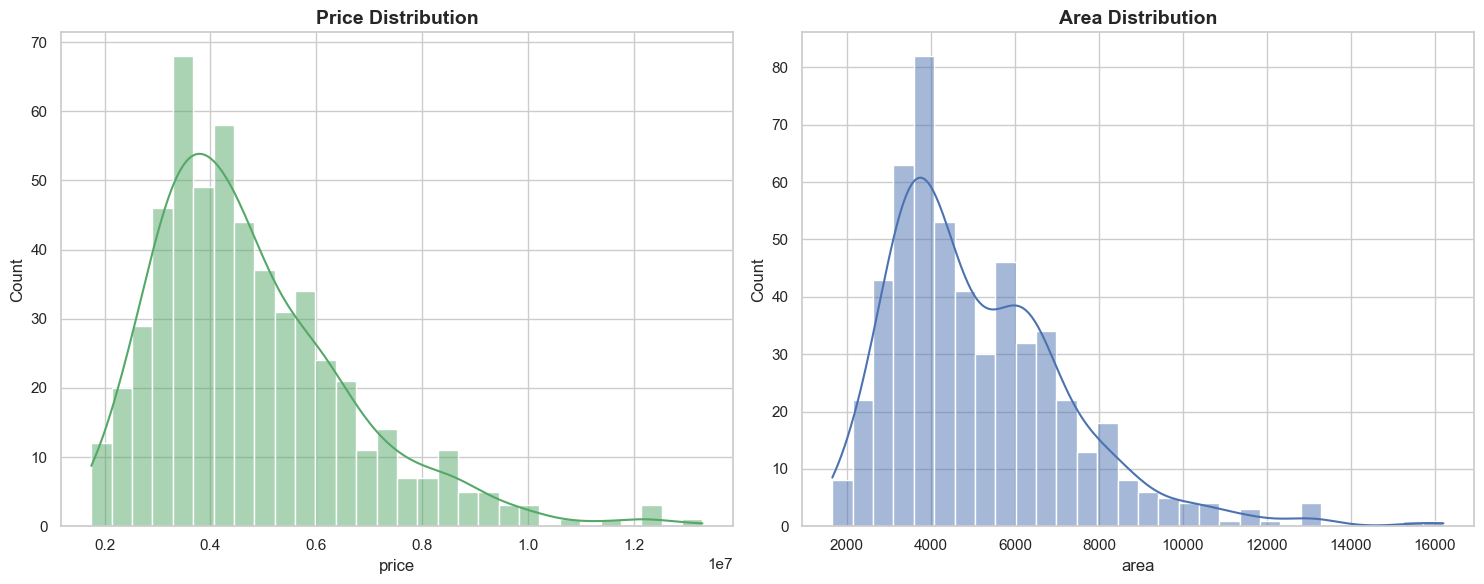

In [194]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(data=df, x='price', bins=30, kde=True, color='g', ax=axs[0])
axs[0].set_title('Price Distribution', fontsize=14, fontweight='bold')

sns.histplot(data=df, x='area', bins=30, kde=True, color='b', ax=axs[1])
axs[1].set_title('Area Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

#### Insights

- **Price:** The distribution is **right-skewed**, with most houses priced between **3M and 6M** (median ≈ 4.34M). A few luxury houses go up to 13.3M, acting as high-end outliers.
- **Area:** Also **right-skewed**, where the majority of houses have an area between **3,000 and 6,500 sq. ft.** (median = 4,600 sq. ft.), with a few large properties reaching up to 16,200 sq. ft..

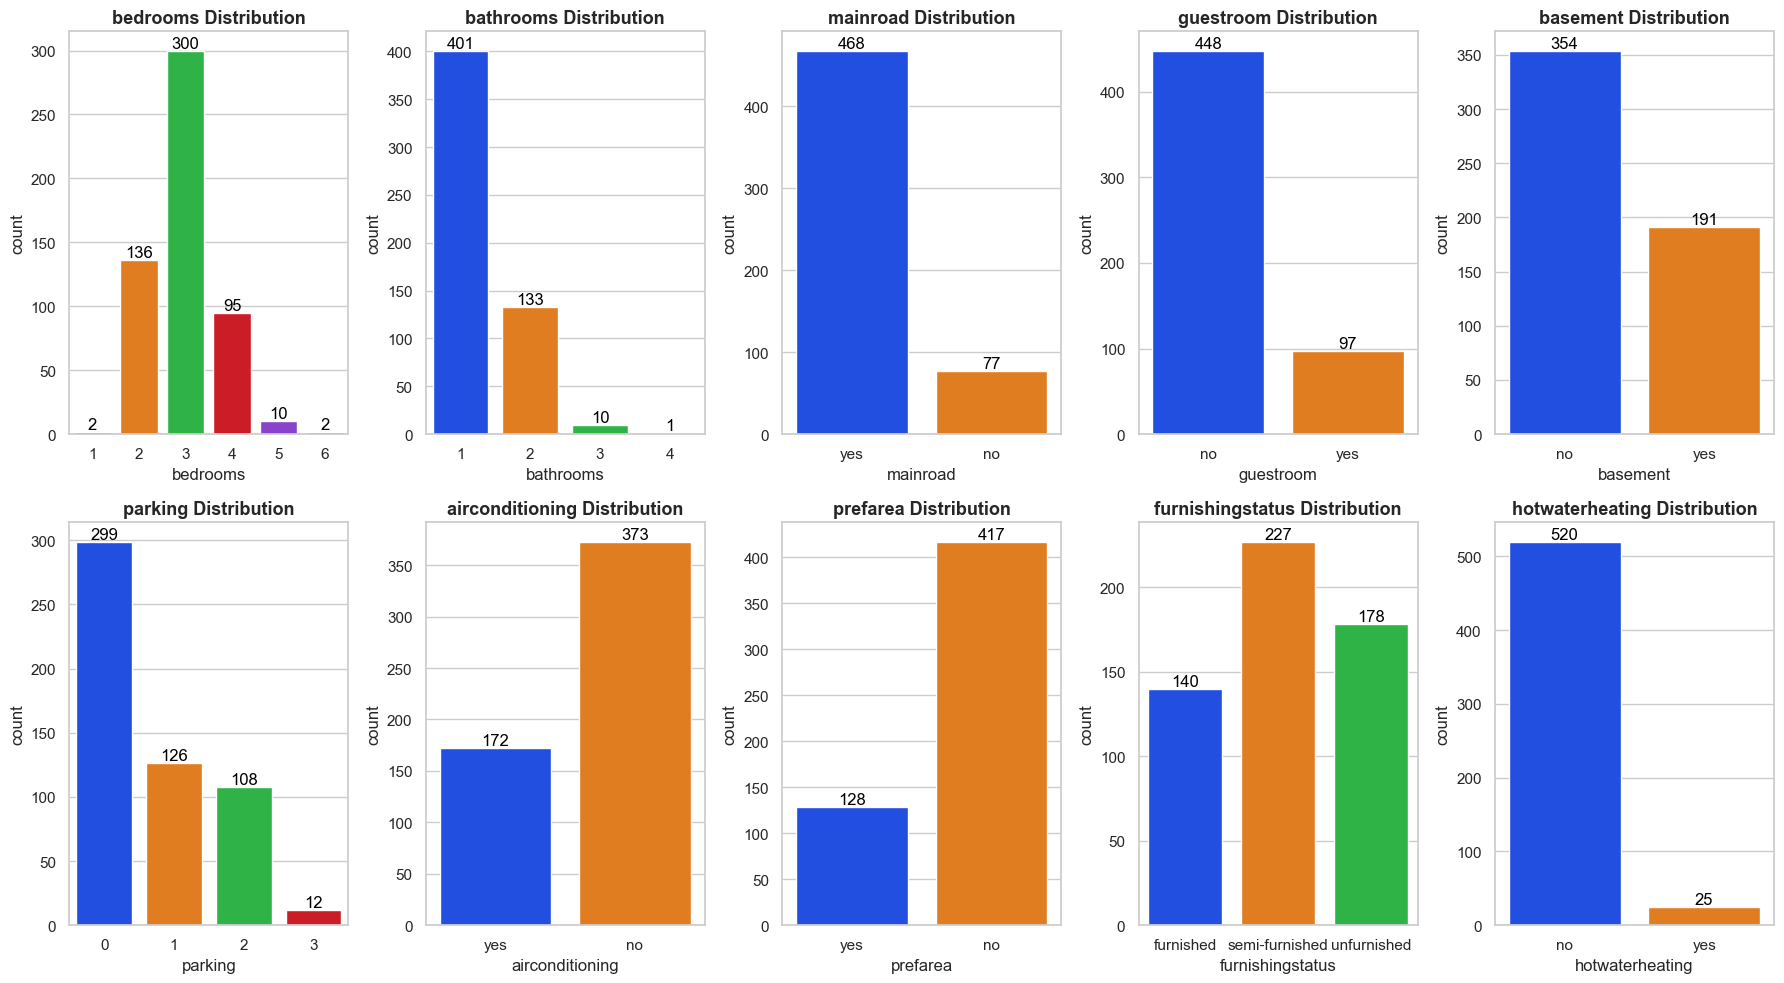

In [195]:
fig, axs = plt.subplots(2, 5, figsize=(18, 10))
axs = axs.flatten()

cols_to_plot = ['bedrooms','bathrooms','mainroad', 'guestroom', 'basement', 'parking','airconditioning', 'prefarea', 'furnishingstatus','hotwaterheating',]

for i, col in enumerate(cols_to_plot):
    sns.countplot(data=df, x=col, palette='bright', ax=axs[i])
    axs[i].set_title(f'{col} Distribution', fontsize=13, fontweight='bold')
    for container in axs[i].containers:
        axs[i].bar_label(container, color='black', size=12)

plt.tight_layout()
plt.show()


#### Insights 
- **Mainroad & Hotwaterheating:** Highly imbalanced — most houses are connected to the main road (`yes`), while very few houses have hot water heating (`yes`).
- **Furnishing Status:** `semi-furnished` houses are the most common, followed by `unfurnished`, and `furnished` houses are the fewest.
- **Air Conditioning & Prefarea:** The majority of houses do not have air conditioning (`no`) and are not in a preferred area (`no`).

#### BIVARIATE ANALYSIS 

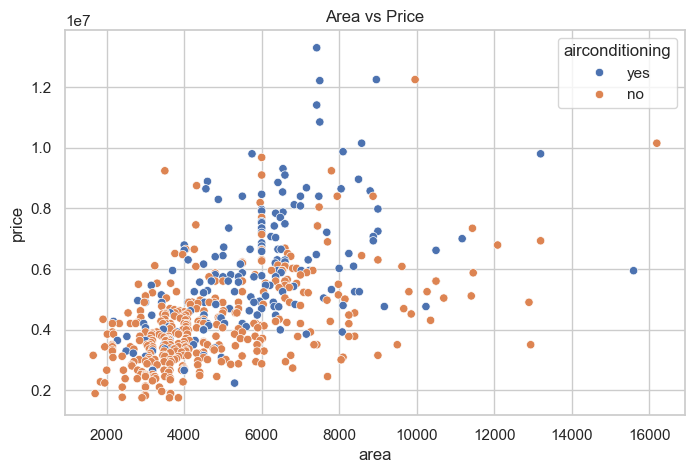

In [196]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='area', y='price', hue='airconditioning')
plt.title("Area vs Price")
plt.show()

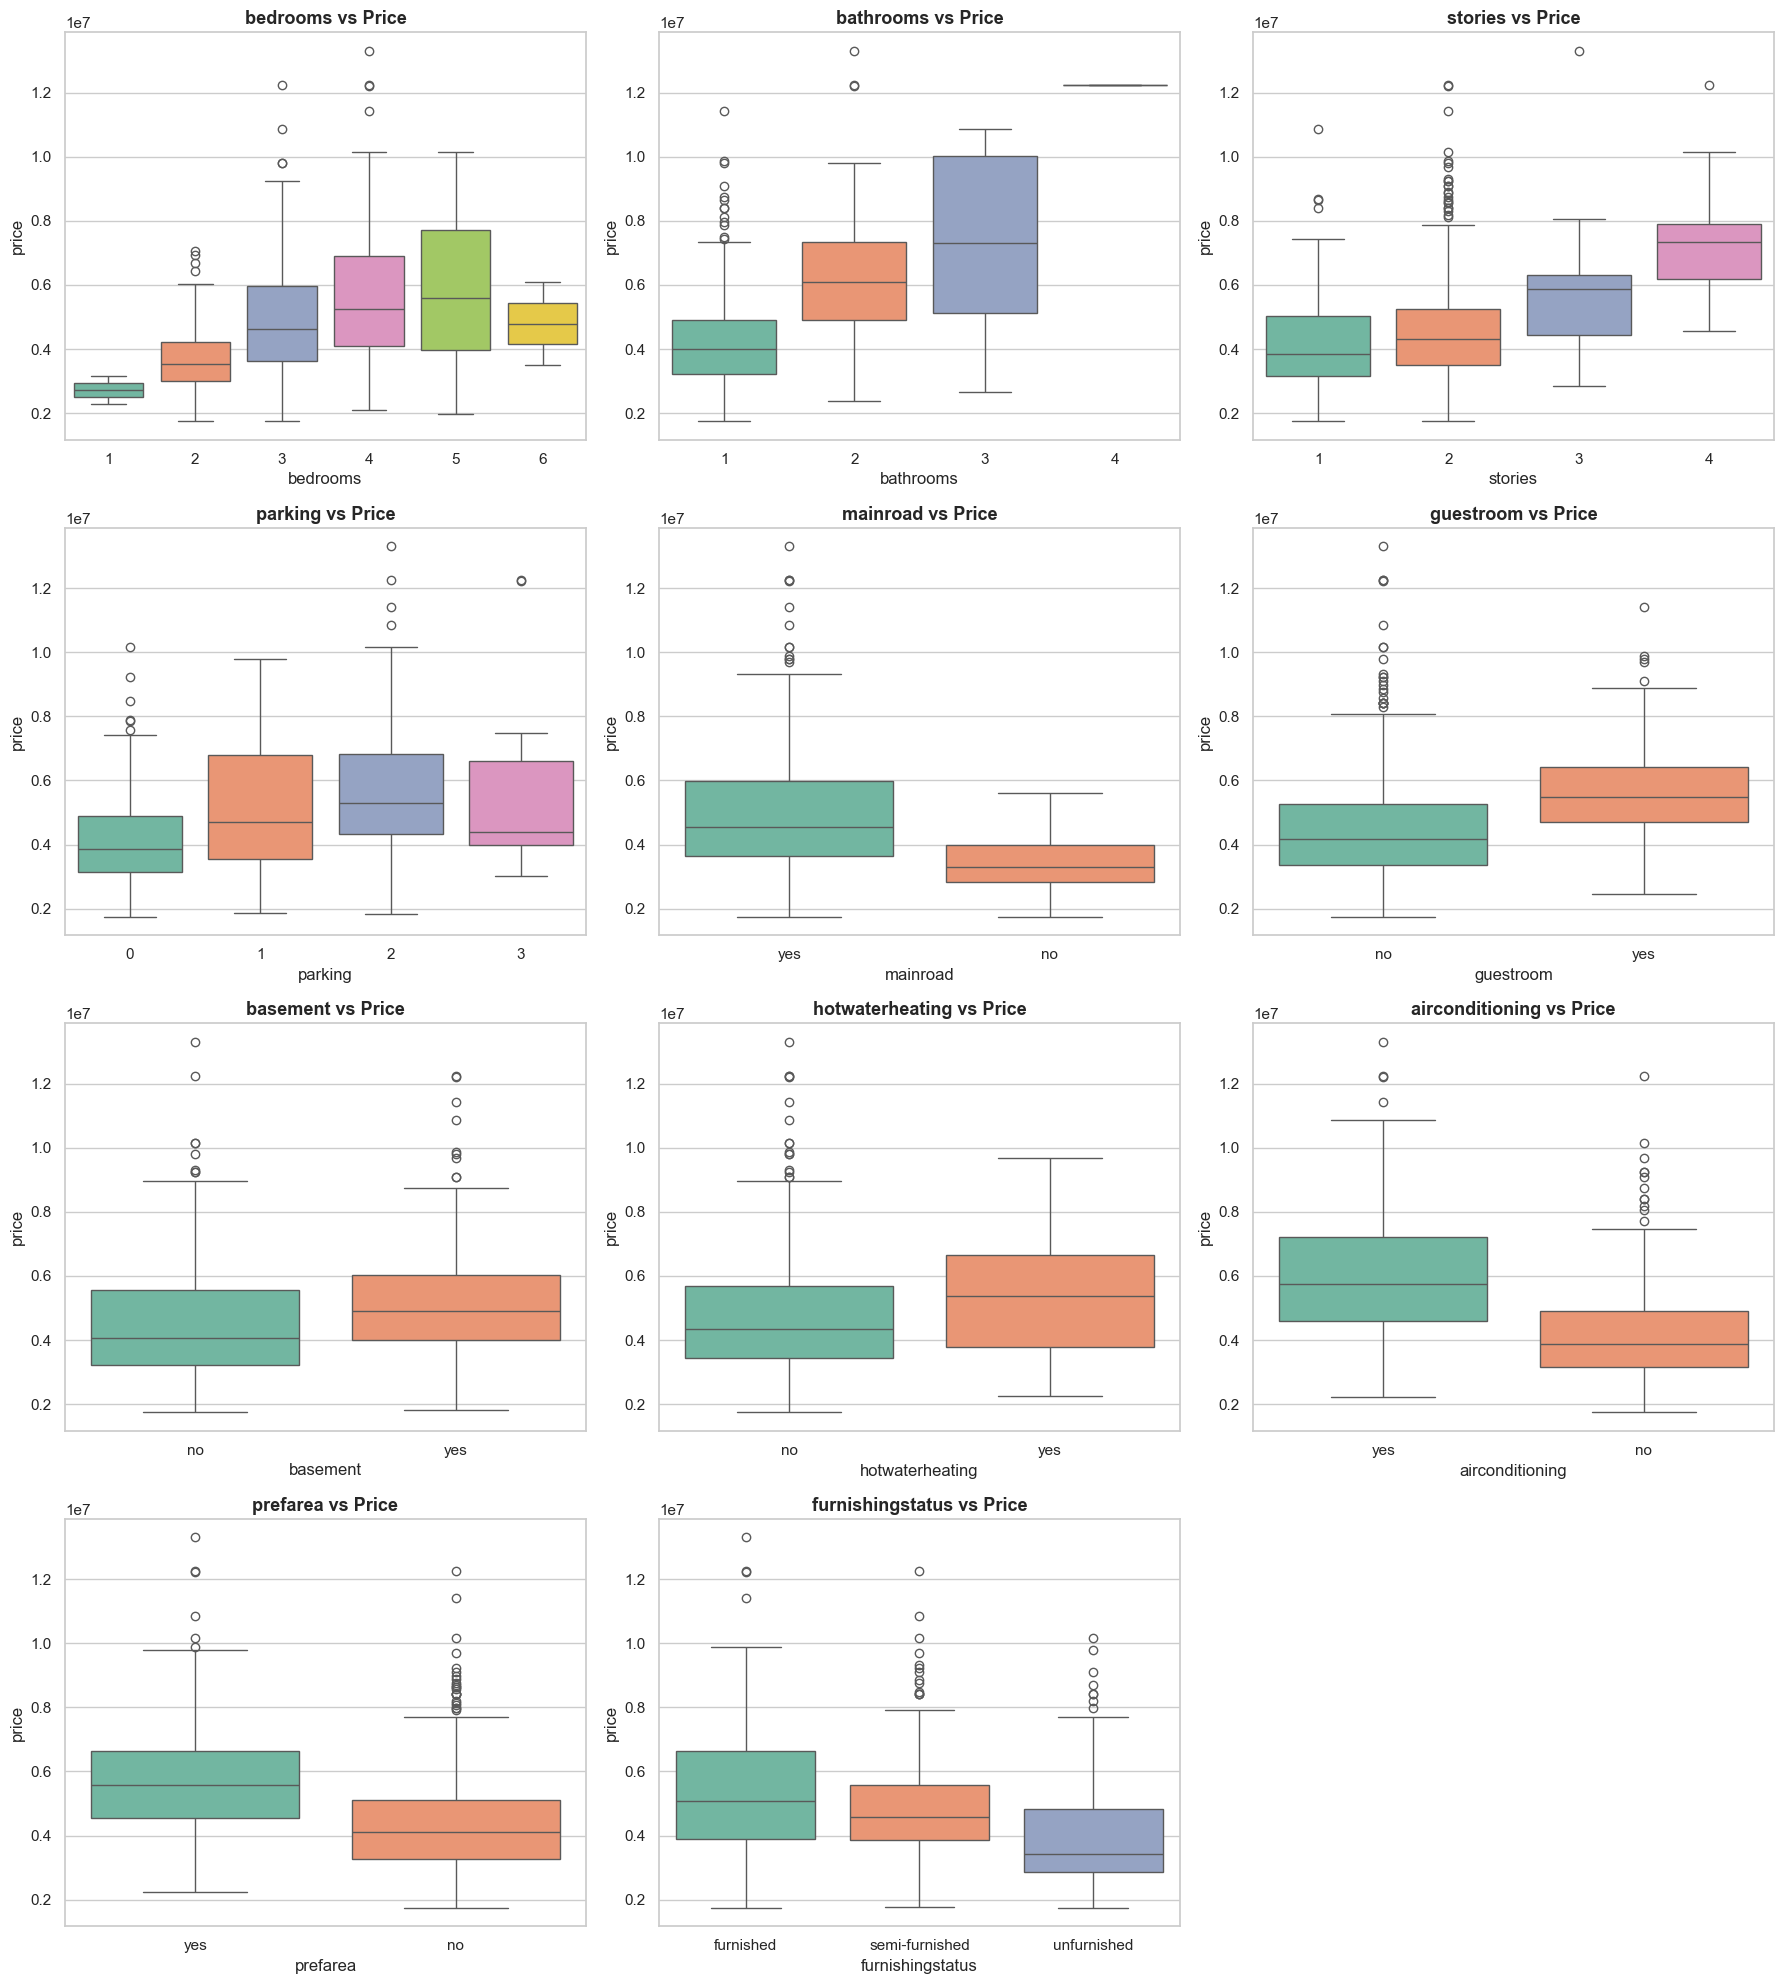

In [197]:
bivar_cols = [
    'bedrooms', 'bathrooms', 'stories', 'parking',
    'mainroad', 'guestroom', 'basement', 'hotwaterheating',
    'airconditioning', 'prefarea', 'furnishingstatus'
]

fig, axs = plt.subplots(4, 3, figsize=(18, 20))
axs = axs.flatten()

for i, col in enumerate(bivar_cols):
    sns.boxplot(data=df, x=col, y='price', palette='Set2', ax=axs[i])
    axs[i].set_title(f'{col} vs Price', fontsize=13, fontweight='bold')


axs[-1].set_visible(False)

plt.tight_layout()
plt.show()

#### Insights (Bivariate Analysis — Features vs Price)
- **Strongest Structural Drivers (`bathrooms`, `stories`):** Median house price increases steadily with more bathrooms (from ~4.0M for 1 bathroom to ~7.3M for 3) and more stories (from ~3.8M for 1 story to ~7.3M for 4).
- **Bedrooms & Parking:** Median price rises from 1 to 5 bedrooms and 0 to 2 parking spaces, then slightly dips at the highest counts (6 bedrooms and 3 parking spaces), likely due to very few data points in those categories.
- **High-Impact Amenities (`airconditioning`, `prefarea`, `guestroom`, `mainroad`):** Houses with air conditioning (~5.7M vs ~3.9M), in a preferred area (~5.6M vs ~4.1M), with a guest room (~5.5M vs ~4.2M), or on a main road (~4.5M vs ~3.3M) command significantly higher median prices.
- **Moderate Impact (`basement`, `hotwaterheating`):** Both show a higher median price for `yes` (~4.9M and ~5.4M) than `no` (~4.0M and ~4.3M), though their price ranges overlap considerably.
- **Furnishing Status:** Shows a clear ordinal trend — `furnished` houses have the highest median price (~5.1M), followed by `semi-furnished` (~4.6M), and `unfurnished` (~3.4M).
- **Outliers:** High-price outliers (10M–13.3M) appear across most categories, confirming the right-skewed nature of `price`.

### Multivariate Analysis
#### correlation heatmap

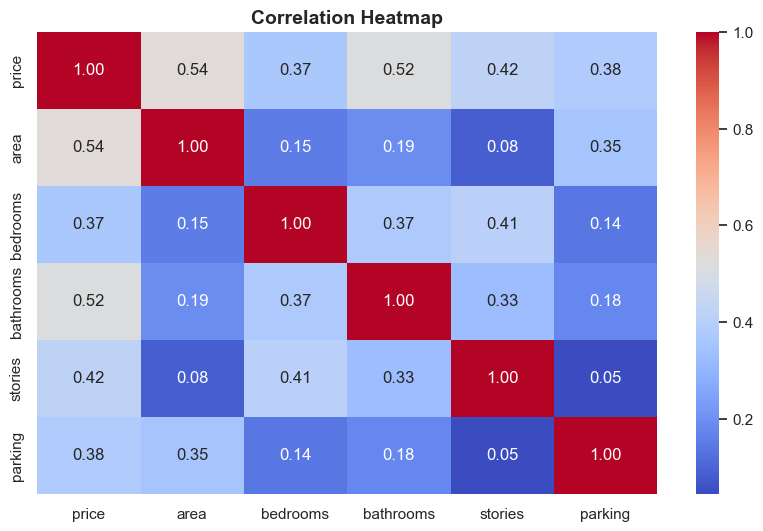

In [198]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

#### Insights (Correlation Heatmap)
- **Top Numerical Predictors:** `area` (0.54) and `bathrooms` (0.52) have the strongest positive correlation with `price`, followed by `stories` (0.42).
- **Weakest Numerical Predictors:** `parking` (0.38) and `bedrooms` (0.37) show relatively lower, though still positive, correlation with `price`.
- **No Multicollinearity:** All feature-to-feature correlations are low to moderate (highest is `bedrooms` vs `stories` at 0.41), meaning all numerical features can safely be used together in linear models without multicollinearity issues.

### 5. Conclusions
- The dataset has 545 rows and 13 columns with no missing or duplicate values.
- `price` and `area` are both right-skewed with some high-end outliers.
- `area`, `bathrooms`, `airconditioning`, `stories`, and `prefarea` show the strongest positive association with house price.
- Categorical features (`yes`/`no` and `furnishingstatus`) need encoding, and numerical features need scaling before model training.